# 01 Exploratory Data Analysis
SMS Spam & Phishing Detection (English + Hinglish). Niraj Bankar (EN25552002), Zaheer Mulani (EN25552018).

This notebook builds the dataset (download, PII masking, label mapping, de-duplication, leakage-safe splits) and reproduces the EDA figures.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_colwidth', 120)

## 1. Build the dataset
Downloads the UCI SMS Spam Collection and the Mishra & Soni SMS Phishing Dataset (both CC BY 4.0), generates the synthetic Hinglish supplement, masks personal data and splits.

In [2]:
from src.data_loader import build_dataset
stats = build_dataset()
print(json.dumps({k: stats[k] for k in ['uci_raw','uci_raw_counts','ms_raw','ms_raw_counts','english_after_dedup','label_conflicts_dropped','english_counts','hinglish_synthetic','hinglish_counts','split_sizes','leakage_text_overlap','leakage_template_overlap']}, indent=1))

{
 "uci_raw": 5574,
 "uci_raw_counts": {
  "ham": 4827,
  "spam": 747
 },
 "ms_raw": 5971,
 "ms_raw_counts": {
  "ham": 4844,
  "phishing": 638,
  "spam": 489
 },
 "english_after_dedup": 5964,
 "label_conflicts_dropped": {
  "within_ms": 37,
  "within_uci": 0,
  "cross_source": 0
 },
 "english_counts": {
  "ham": 5057,
  "spam": 474,
  "phishing": 433
 },
 "hinglish_synthetic": 357,
 "hinglish_counts": {
  "phishing": 131,
  "ham": 126,
  "spam": 100
 },
 "split_sizes": {
  "train": 4419,
  "val": 957,
  "test": 945
 },
 "leakage_text_overlap": {
  "train_val": 0,
  "train_test": 0,
  "val_test": 0
 },
 "leakage_template_overlap": {
  "train_test": 0,
  "train_val": 0
 }
}


## 2. Inspect processed data
Phone numbers, URLs, e-mails and long digit runs are already replaced by `<phone>`, `<url>`, `<email>`, `<num>`.

In [3]:
train = pd.read_csv('data/processed/train.csv', keep_default_na=False)
print(train.shape); print(train.isna().sum().sum(), 'missing values')
train.groupby(['language','label']).size().unstack()

(4419, 9)
0 missing values


label,ham,phishing,spam
language,,,
english,3539,303,332
hinglish,85,89,71


In [4]:
train.sample(8, random_state=3)[['text','label','language','source']]

,text,label,language,source
3216,Yup. Hey then one day on fri we can ask miwa and jiayin take leave go karaoke,ham,english,uci+mishra_soni
240,No need lar. Jus testing e phone card. Dunno network not gd i thk. Me waiting 4 my sis 2 finish bathing so i can bat...,ham,english,uci+mishra_soni
3440,A £400 XMAS REWARD IS WAITING FOR YOU! Our computer has randomly picked you from our loyal mobile customers to recei...,phishing,english,uci+mishra_soni
2471,Pls dont restrict her from eating anythin she likes for the next two days.,ham,english,uci+mishra_soni
3017,"Dizzamn, aight I'll ask my suitemates when I get back",ham,english,uci+mishra_soni
3936,what is your account number?,ham,english,uci+mishra_soni
379,I've sent ü my part.,ham,english,uci
4134,Hahaha.use your brain dear.thats important,ham,english,mishra_soni


## 3. Preprocessing examples

In [5]:
from src.preprocessing import mask_pii, clean_text, is_hinglish
for s in ['URGENT!!! Your SBI a/c will be BLOCKED. Update KYC at http://sbi-kyc.example/verify or call +91 5555501234',
          'Aapka SBI account band ho jayega. KYC update karne ke liye abhi link open karo.',
          'Kal college lecture 10 baje hai, time pe aa jana.']:
    print('hinglish' if is_hinglish(s) else 'english', '|', clean_text(s))

english | urgent! your sbi account will be blocked. update kyc at <url> or call <phone>
hinglish | aapka sbi account band ho jayega. kyc update karne ke liye abhi link open karo.
hinglish | kal college lecture 10 baje hai, time pe aa jana.


## 4. Figures

Saved EDA figures to /Users/abhijeetsuryawanshi/Desktop/Niraj Projects/sms-spam-phishing-detection/results/graphs


**01_class_distribution.png**

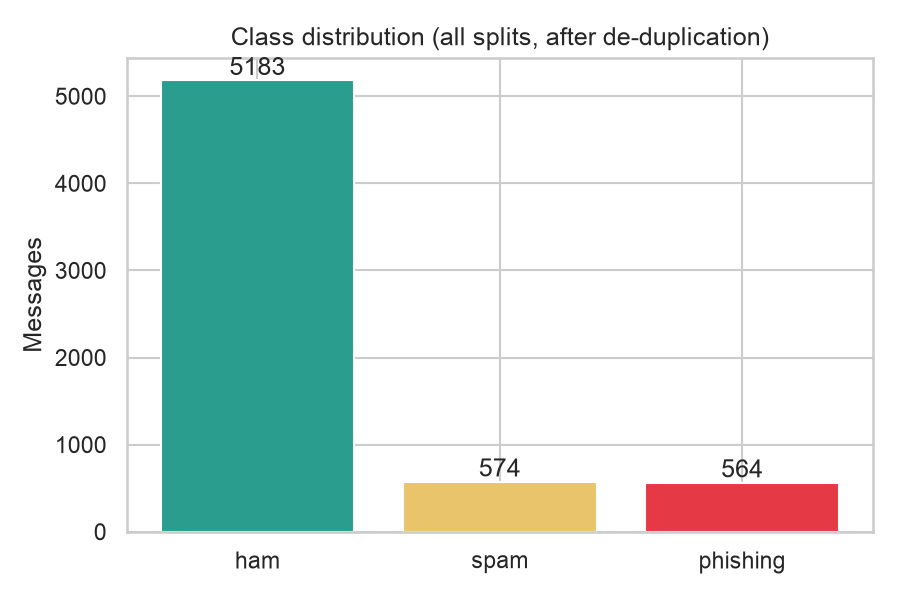

**02_class_by_split_and_language.png**

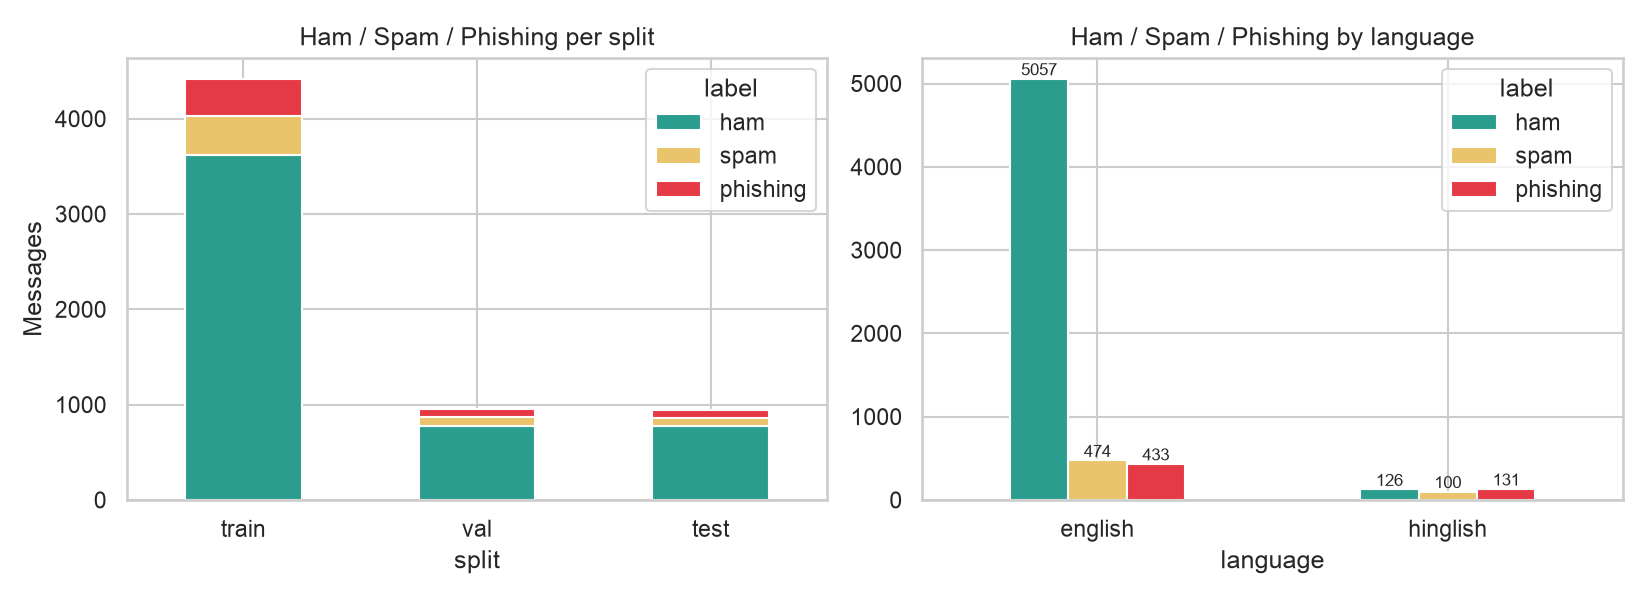

**03_label_mapping.png**

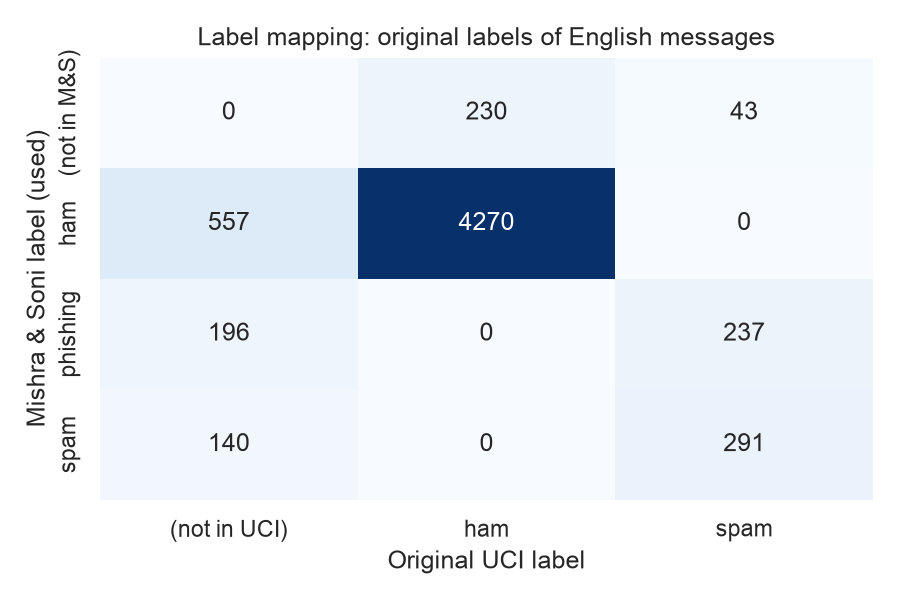

**04_message_length.png**

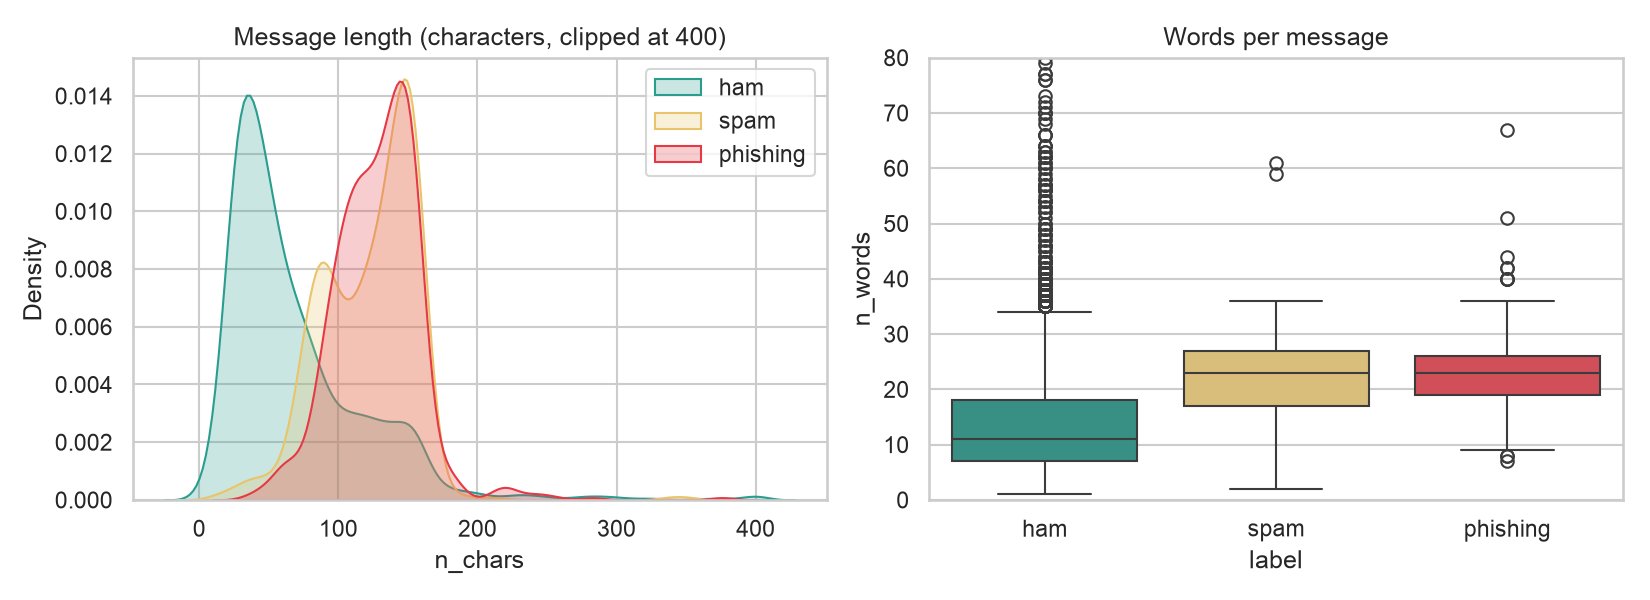

**05_top_words.png**

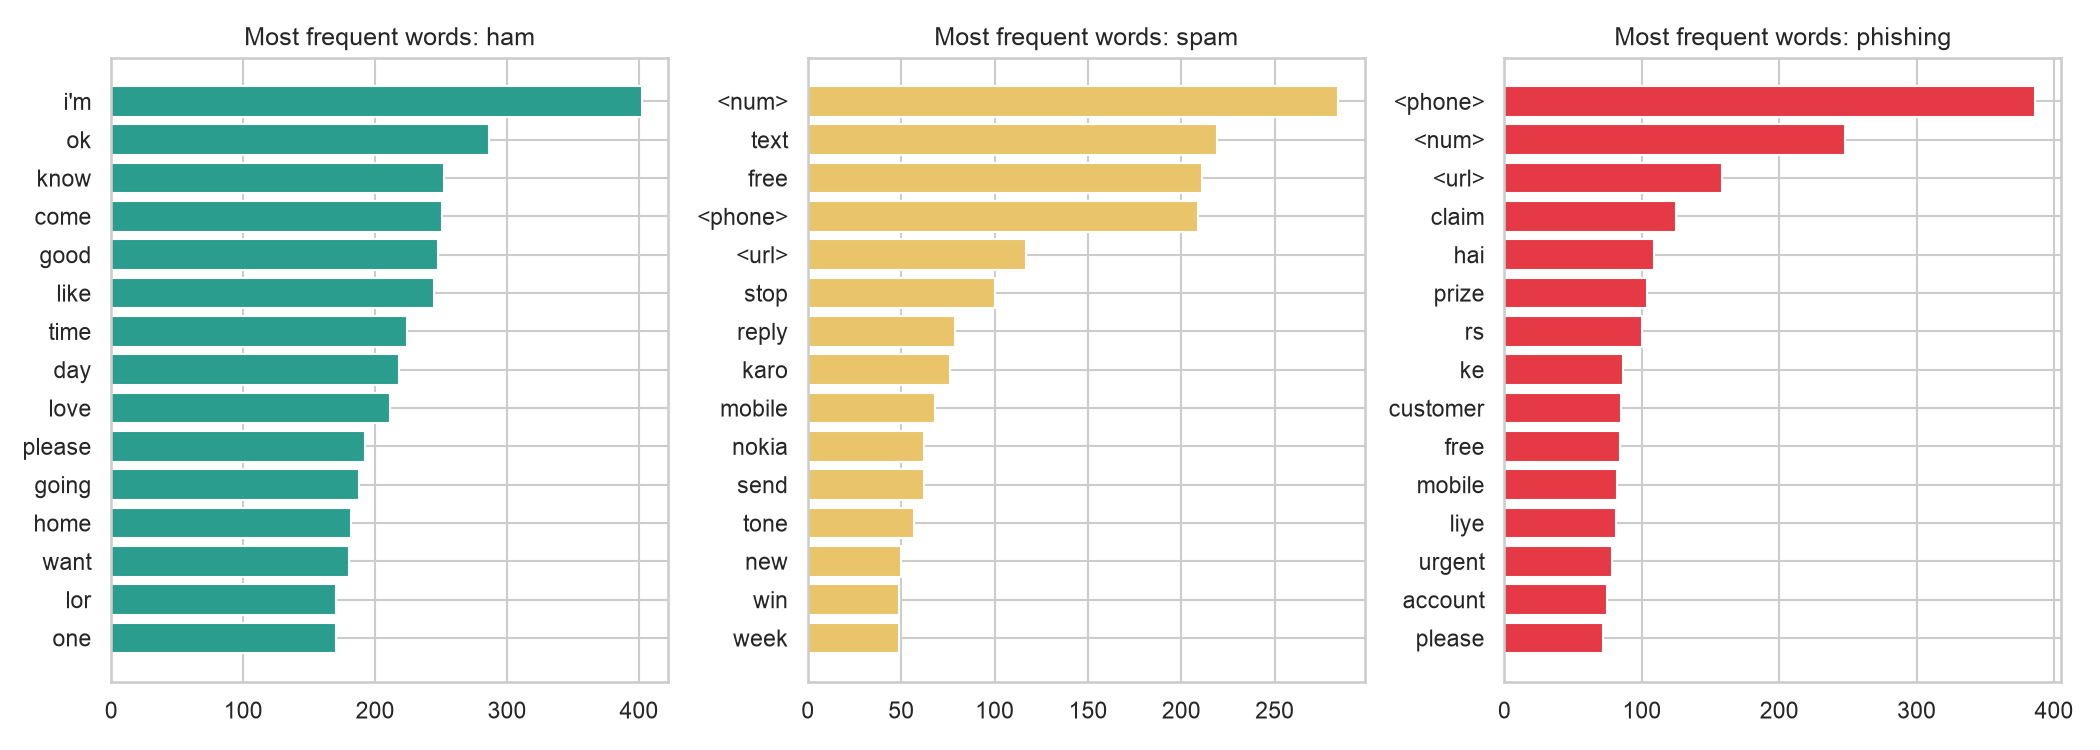

**06_wordclouds.png**

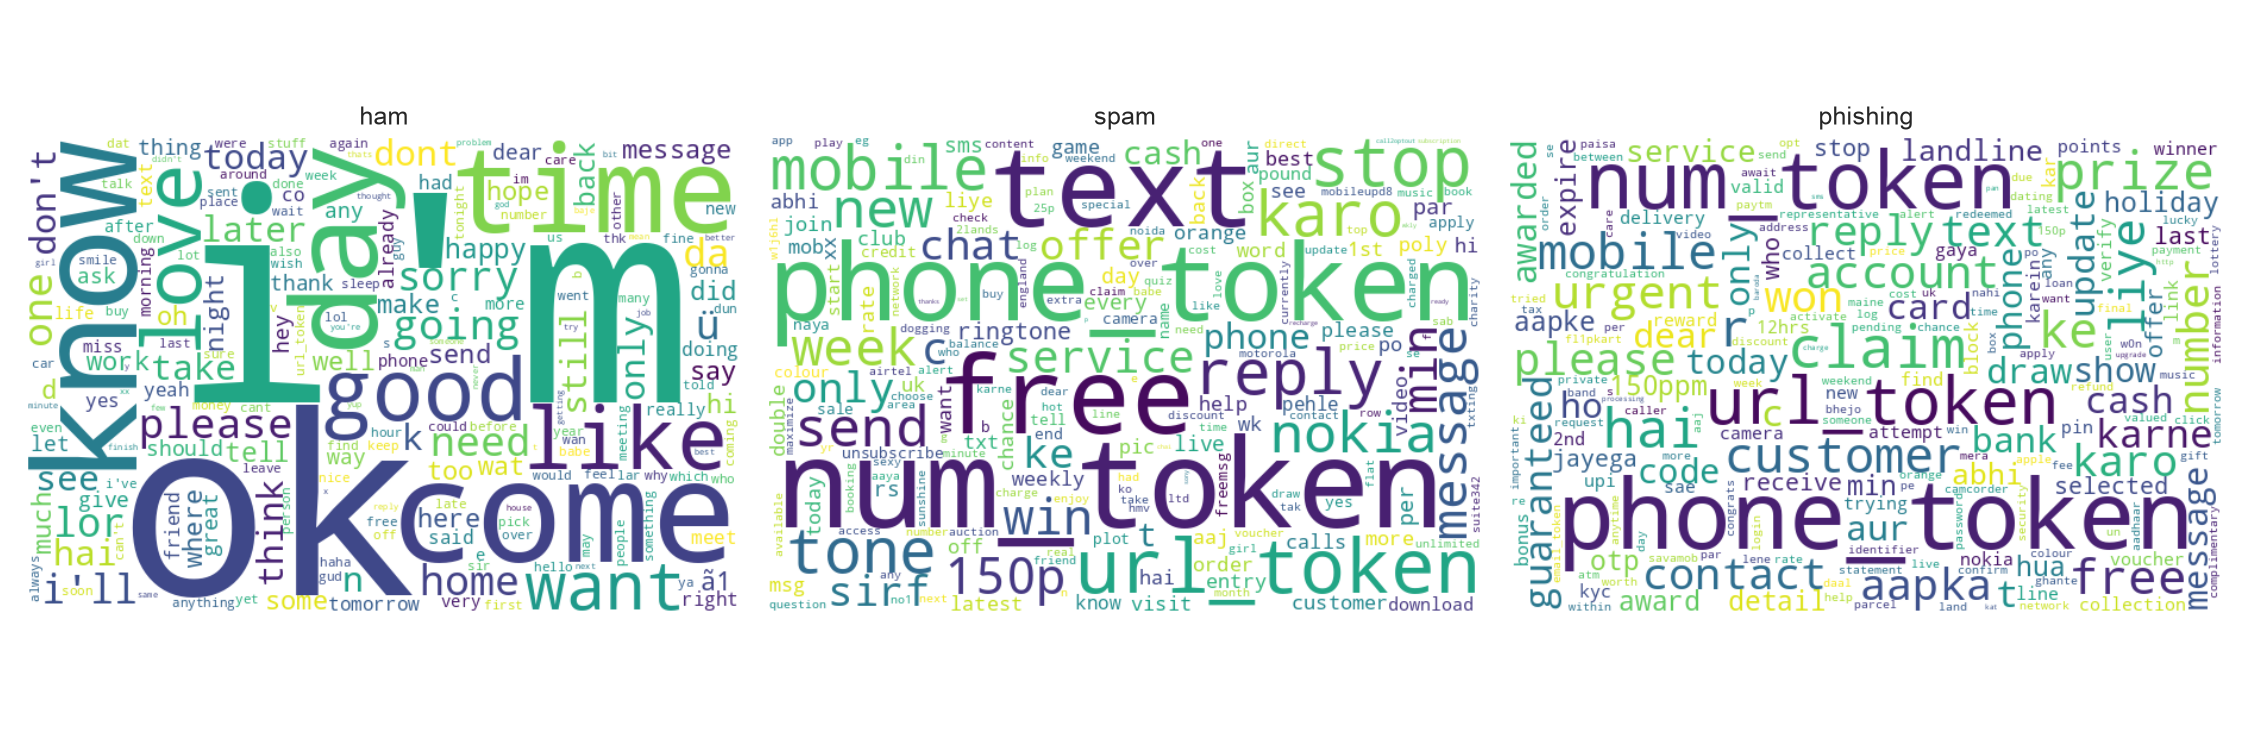

**07_language_and_source.png**

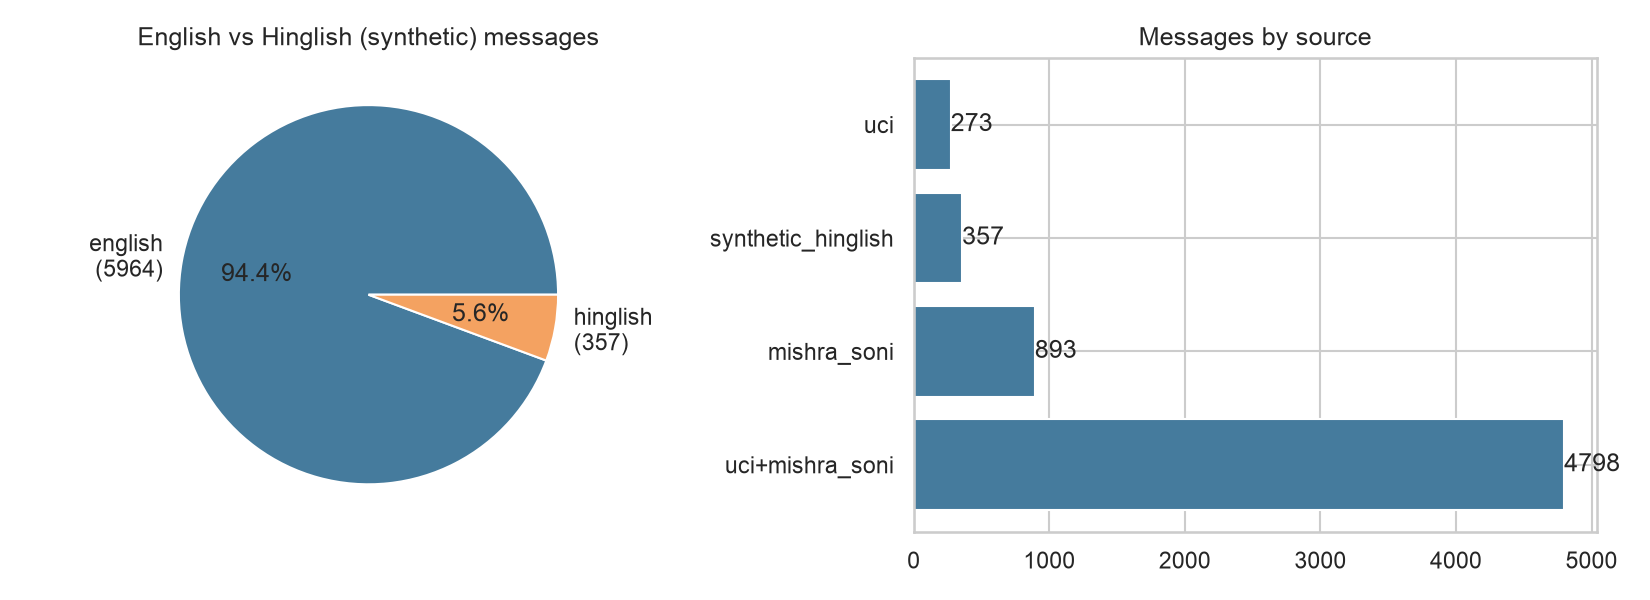

**08_placeholder_tokens.png**

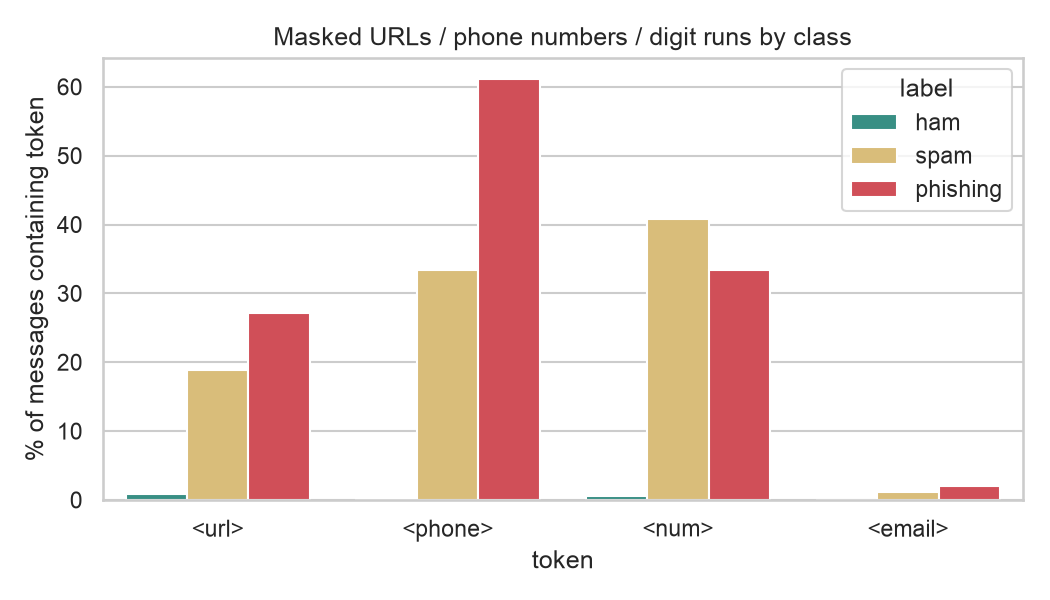

In [6]:
from src import eda
eda.main()
for f in sorted(Path('results/graphs').glob('0*.png')):
    display(Markdown(f'**{f.name}**')); display(Image(str(f), width=900))